# Evaluation Metrics for NLP — Hands-on with Real Datasets
**Master Data & IA · ML Evaluation · INPT · 2026 — Kaoutar Chakroun**

This notebook applies the metrics from the presentation to **real datasets**:

| Part | Task | Dataset | Model |
|---|---|---|---|
| 1 | Binary classification (sentiment) | NLTK *Movie Reviews* — 2,000 IMDb reviews | TF-IDF + Logistic Regression |
| 2 | Multi-class classification (topics) | NLTK *Reuters-21578* — news articles | TF-IDF + Logistic Regression |
| 3 | Sequence labeling (NER) | *CoNLL-2002* Spanish NER (BIO tags) | Conditional Random Field (CRF) |
| 4 | Machine translation (FR → EN) | *ComTrans* — Europarl French–English sentence pairs | IBM Model 1 (statistical MT) |

In [1]:
# On Google Colab, uncomment the next line
# !pip install -q scikit-learn sklearn-crfsuite seqeval sacrebleu nltk matplotlib seaborn

In [2]:
import warnings, random, collections, re
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import nltk
for pkg in ["movie_reviews", "reuters", "conll2002", "comtrans", "wordnet", "omw-1.4", "punkt"]:
    nltk.download(pkg, quiet=True)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
RNG = 42; random.seed(RNG); np.random.seed(RNG)

---
## Part 1 — Binary classification: sentiment analysis
**Dataset:** 2,000 movie reviews labelled *positive* or *negative*. We train a TF-IDF + Logistic Regression classifier and evaluate it with **accuracy, precision, recall, F1, the confusion matrix, ROC-AUC** and the **precision–recall trade-off**.

In [3]:
from nltk.corpus import movie_reviews
docs   = [movie_reviews.raw(f) for f in movie_reviews.fileids()]
labels = [1 if f.startswith("pos") else 0 for f in movie_reviews.fileids()]
df = pd.DataFrame({"text": docs, "label": labels})
print(df.shape); df["label"].map({1: "positive", 0: "negative"}).value_counts()

(2000, 2)


label
negative    1000
positive    1000
Name: count, dtype: int64

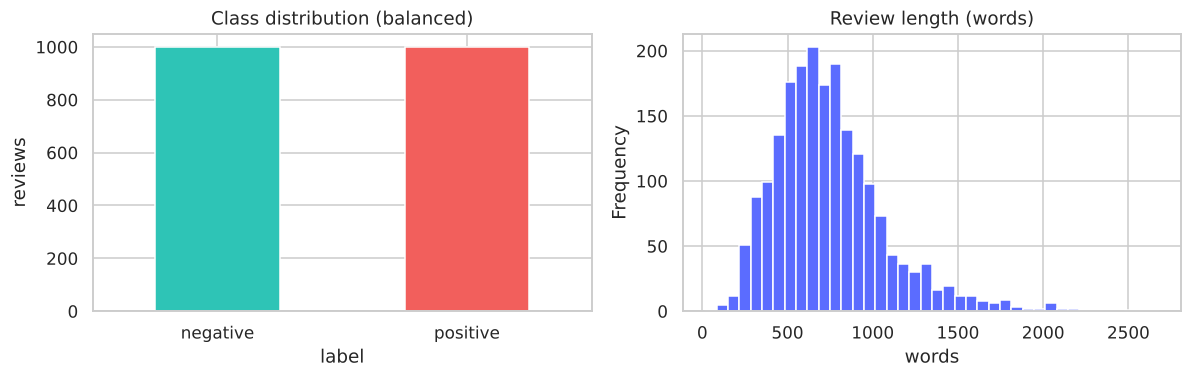

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df["label"].map({1: "positive", 0: "negative"}).value_counts().plot.bar(ax=ax[0], color=["#2EC4B6", "#F25F5C"], rot=0)
ax[0].set_title("Class distribution (balanced)"); ax[0].set_ylabel("reviews")
df["text"].str.split().str.len().plot.hist(bins=40, ax=ax[1], color="#5B6CFF")
ax[1].set_title("Review length (words)"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

X_tr, X_te, y_tr, y_te = train_test_split(df["text"], df["label"], test_size=0.25, stratify=df["label"], random_state=RNG)
clf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(max_iter=2000, C=10))
clf.fit(X_tr, y_tr)
y_pred  = clf.predict(X_te)
y_proba = clf.predict_proba(X_te)[:, 1]
print(f"train = {len(X_tr)} reviews, test = {len(X_te)} reviews")

train = 1500 reviews, test = 500 reviews


### 1.1 Accuracy, precision, recall, F1

In [6]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)
scores = {"Accuracy": accuracy_score(y_te, y_pred), "Precision": precision_score(y_te, y_pred),
          "Recall": recall_score(y_te, y_pred), "F1": f1_score(y_te, y_pred), "ROC-AUC": roc_auc_score(y_te, y_proba)}
for k, v in scores.items(): print(f"{k:10s}: {v:.3f}")
print(); print(classification_report(y_te, y_pred, target_names=["negative", "positive"]))

Accuracy  : 0.864
Precision : 0.864
Recall    : 0.864
F1        : 0.864
ROC-AUC   : 0.943

              precision    recall  f1-score   support

    negative       0.86      0.86      0.86       250
    positive       0.86      0.86      0.86       250

    accuracy                           0.86       500
   macro avg       0.86      0.86      0.86       500
weighted avg       0.86      0.86      0.86       500



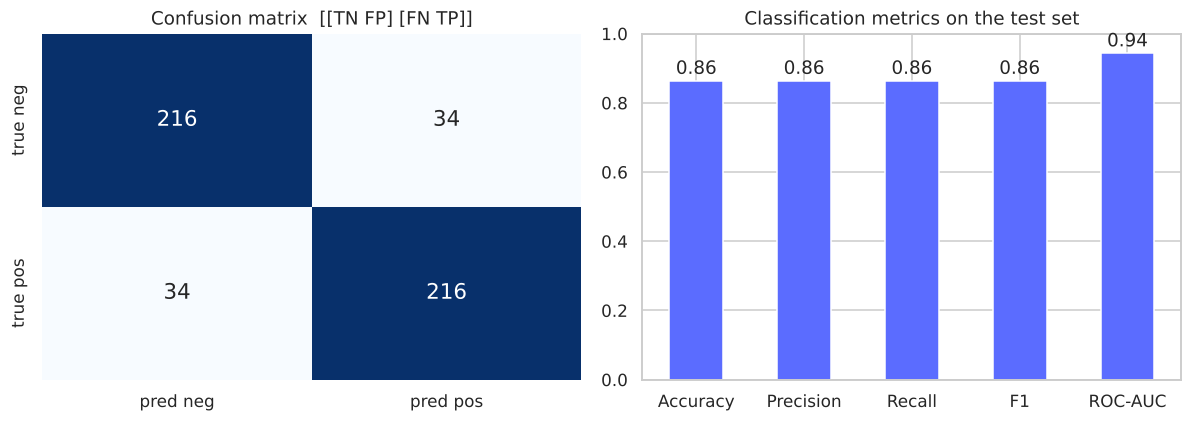

In [7]:
cm = confusion_matrix(y_te, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["pred neg", "pred pos"], yticklabels=["true neg", "true pos"], annot_kws={"size": 14})
ax[0].set_title("Confusion matrix  [[TN FP] [FN TP]]")
pd.Series(scores).plot.bar(ax=ax[1], color="#5B6CFF", rot=0, ylim=(0, 1))
for i, v in enumerate(scores.values()): ax[1].text(i, v + 0.02, f"{v:.2f}", ha="center")
ax[1].set_title("Classification metrics on the test set")
plt.tight_layout(); plt.show()

### 1.2 ROC curve and precision–recall curve
ROC-AUC evaluates the **probabilities**, independently of the 0.5 threshold.

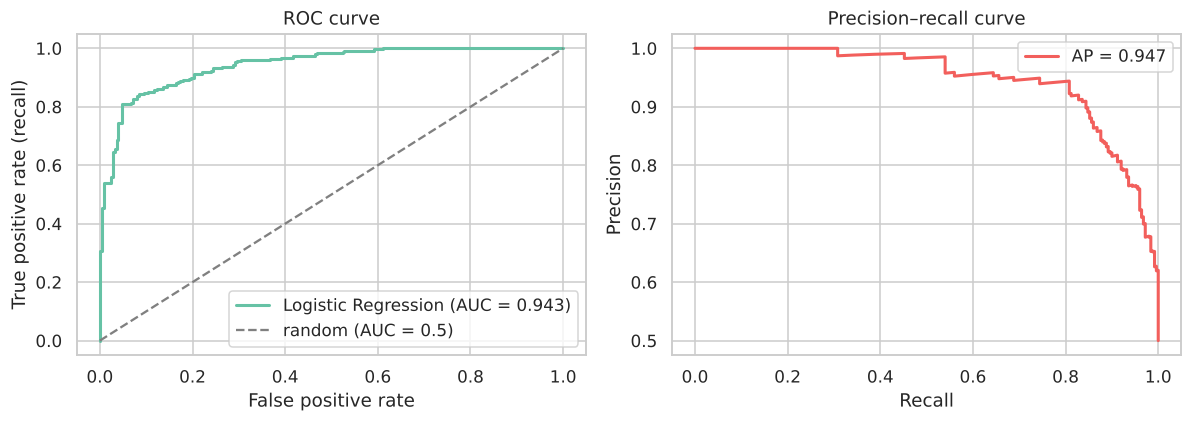

In [8]:
fpr, tpr, _ = roc_curve(y_te, y_proba)
prec, rec, thr = precision_recall_curve(y_te, y_proba)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr, lw=2, label=f"Logistic Regression (AUC = {roc_auc_score(y_te, y_proba):.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="random (AUC = 0.5)")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve"); ax[0].legend()
ax[1].plot(rec, prec, lw=2, color="#F25F5C", label=f"AP = {average_precision_score(y_te, y_proba):.3f}")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve"); ax[1].legend()
plt.tight_layout(); plt.show()

### 1.3 Precision or recall? Moving the decision threshold
A higher threshold → fewer false alarms (precision ↑) but more misses (recall ↓). F1 finds the balance.

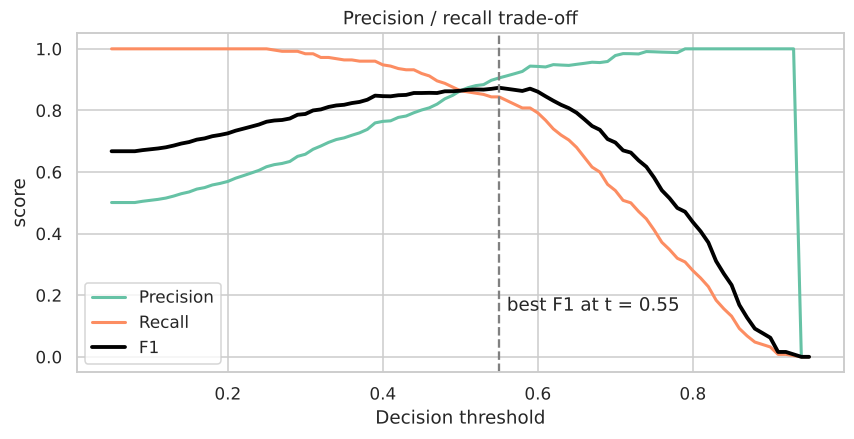

In [9]:
ths = np.linspace(0.05, 0.95, 91)
P = [precision_score(y_te, y_proba >= t, zero_division=0) for t in ths]
R = [recall_score(y_te, y_proba >= t) for t in ths]
F = [f1_score(y_te, y_proba >= t) for t in ths]
best = ths[int(np.argmax(F))]
plt.figure(figsize=(9, 4))
plt.plot(ths, P, label="Precision", lw=2); plt.plot(ths, R, label="Recall", lw=2); plt.plot(ths, F, label="F1", lw=2.5, color="black")
plt.axvline(best, ls="--", color="gray"); plt.text(best + 0.01, 0.15, f"best F1 at t = {best:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("score"); plt.title("Precision / recall trade-off"); plt.legend(); plt.show()

### 1.4 The accuracy trap on imbalanced data
We keep all negative reviews and **remove positive reviews** to make them rarer and rarer (50 % → 5 %).
We compare our model with a *dummy* model that always predicts the majority class.

In [10]:
from sklearn.dummy import DummyClassifier
rows = []
neg, pos = df[df.label == 0], df[df.label == 1]
for ratio in [0.5, 0.3, 0.2, 0.1, 0.05]:
    n_pos = int(len(neg) * ratio / (1 - ratio))
    d = pd.concat([neg, pos.sample(n_pos, random_state=RNG)])
    a, b, ya, yb = train_test_split(d.text, d.label, test_size=0.3, stratify=d.label, random_state=RNG)
    for name, model in [("Logistic Regression (class_weight=balanced)", make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), LogisticRegression(max_iter=2000, C=10, class_weight="balanced"))),
                        ("Dummy (always majority)", DummyClassifier(strategy="most_frequent"))]:
        p = model.fit(a, ya).predict(b)
        rows.append({"positive share": f"{int(ratio*100)}%", "model": name, "Accuracy": accuracy_score(yb, p),
                     "F1 (positive)": f1_score(yb, p, zero_division=0), "Macro-F1": f1_score(yb, p, average="macro")})
imb = pd.DataFrame(rows); imb.round(3)

,positive share,model,Accuracy,F1 (positive),Macro-F1
0,50%,Logistic Regression (class_weight=balanced),0.865,0.864,0.865
1,50%,Dummy (always majority),0.500,0.000,0.333
2,30%,Logistic Regression (class_weight=balanced),0.876,0.776,0.846
3,30%,Dummy (always majority),0.699,0.000,0.412
4,20%,Logistic Regression (class_weight=balanced),0.861,0.509,0.714
5,20%,Dummy (always majority),0.800,0.000,0.444
6,10%,Logistic Regression (class_weight=balanced),0.913,0.256,0.605
7,10%,Dummy (always majority),0.901,0.000,0.474
8,5%,Logistic Regression (class_weight=balanced),0.949,0.000,0.487
9,5%,Dummy (always majority),0.949,0.000,0.487


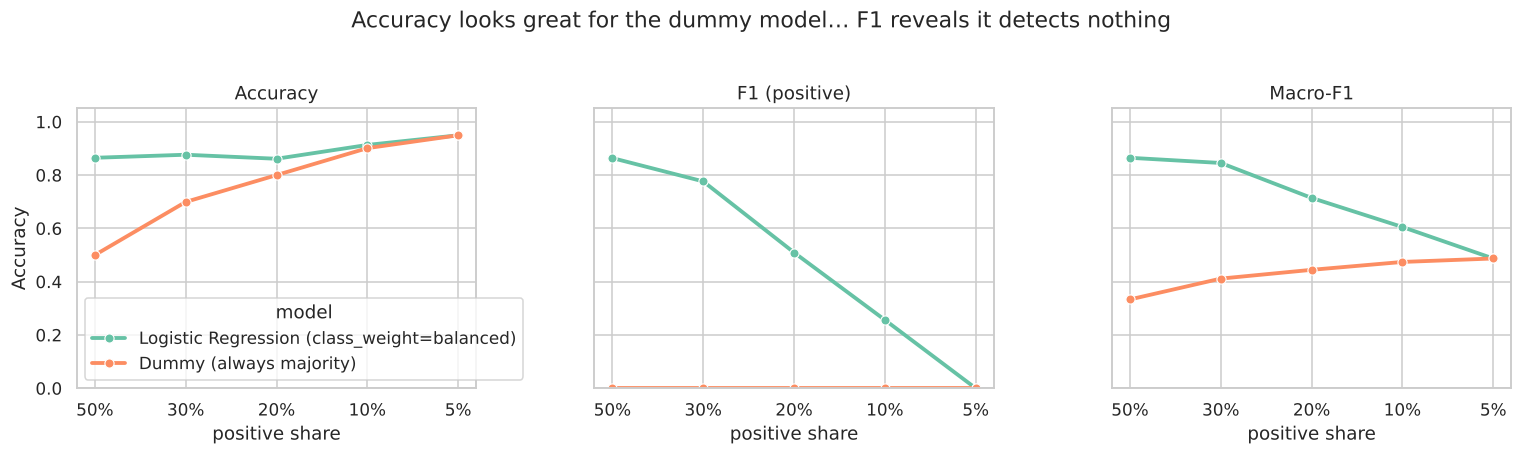

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for i, m in enumerate(["Accuracy", "F1 (positive)", "Macro-F1"]):
    sns.lineplot(data=imb, x="positive share", y=m, hue="model", marker="o", lw=2.5, ax=ax[i], legend=(i == 0))
    ax[i].set_title(m); ax[i].set_ylim(0, 1.05)
plt.suptitle("Accuracy looks great for the dummy model… F1 reveals it detects nothing", y=1.03); plt.tight_layout(); plt.show()

---
## Part 2 — Multi-class classification: news topics (Reuters)
**Dataset:** Reuters-21578 news articles with a single topic among the 8 most frequent topics. The classes are **very imbalanced**, which is exactly where **micro- vs macro-averaging** matter.

train = 5557, test = 2205


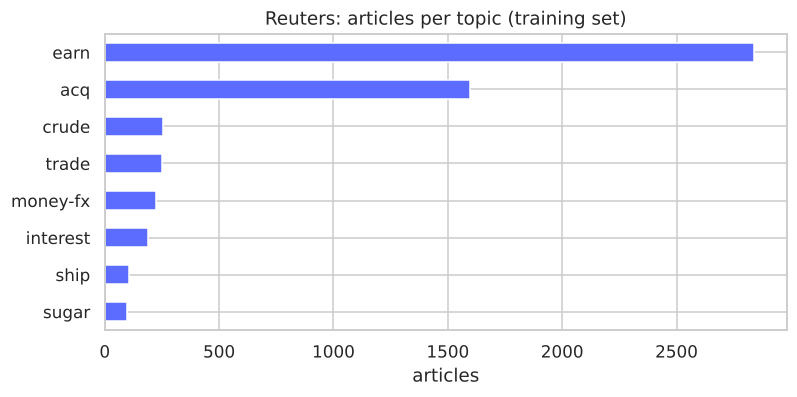

In [12]:
from nltk.corpus import reuters
TOP = ["earn", "acq", "crude", "trade", "money-fx", "interest", "ship", "sugar"]
def load(split):
    ids = [f for f in reuters.fileids() if f.startswith(split) and len(reuters.categories(f)) == 1 and reuters.categories(f)[0] in TOP]
    return [reuters.raw(f) for f in ids], [reuters.categories(f)[0] for f in ids]
Xr_tr, yr_tr = load("training"); Xr_te, yr_te = load("test")
print(f"train = {len(Xr_tr)}, test = {len(Xr_te)}")
pd.Series(yr_tr).value_counts().plot.barh(figsize=(8, 3.5), color="#5B6CFF", title="Reuters: articles per topic (training set)")
plt.gca().invert_yaxis(); plt.xlabel("articles"); plt.show()

In [13]:
clf_r = make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2), LogisticRegression(max_iter=3000))
yr_pred = clf_r.fit(Xr_tr, yr_tr).predict(Xr_te)
print(classification_report(yr_te, yr_pred, digits=3))

              precision    recall  f1-score   support

         acq      0.927     0.987     0.956       696
       crude      0.964     0.893     0.927       121
        earn      0.983     0.988     0.986      1083
    interest      0.949     0.691     0.800        81
    money-fx      0.821     0.793     0.807        87
        ship      1.000     0.500     0.667        36
       sugar      1.000     0.840     0.913        25
       trade      0.890     0.961     0.924        76

    accuracy                          0.953      2205
   macro avg      0.942     0.832     0.872      2205
weighted avg      0.954     0.953     0.951      2205



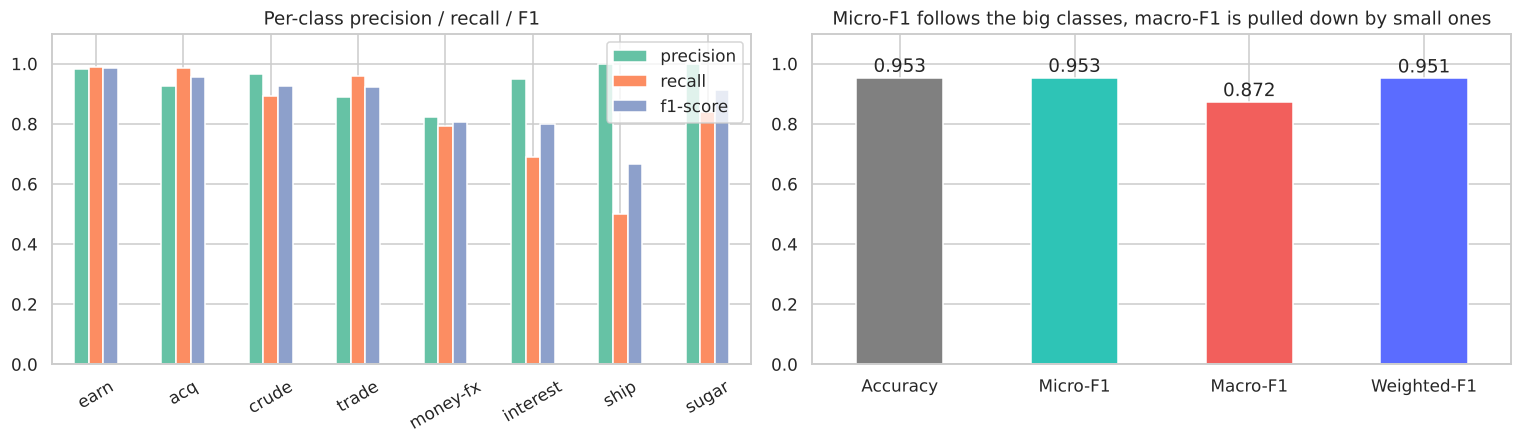

In [14]:
rep = pd.DataFrame(classification_report(yr_te, yr_pred, output_dict=True)).T.loc[TOP]
avg = {"Accuracy": accuracy_score(yr_te, yr_pred), **{f"{a.capitalize()}-F1": f1_score(yr_te, yr_pred, average=a) for a in ["micro", "macro", "weighted"]}}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
rep[["precision", "recall", "f1-score"]].plot.bar(ax=ax[0], rot=30, ylim=(0, 1.1)); ax[0].set_title("Per-class precision / recall / F1")
pd.Series(avg).plot.bar(ax=ax[1], rot=0, ylim=(0, 1.1), color=["gray", "#2EC4B6", "#F25F5C", "#5B6CFF"])
for i, v in enumerate(avg.values()): ax[1].text(i, v + 0.02, f"{v:.3f}", ha="center")
ax[1].set_title("Micro-F1 follows the big classes, macro-F1 is pulled down by small ones")
plt.tight_layout(); plt.show()

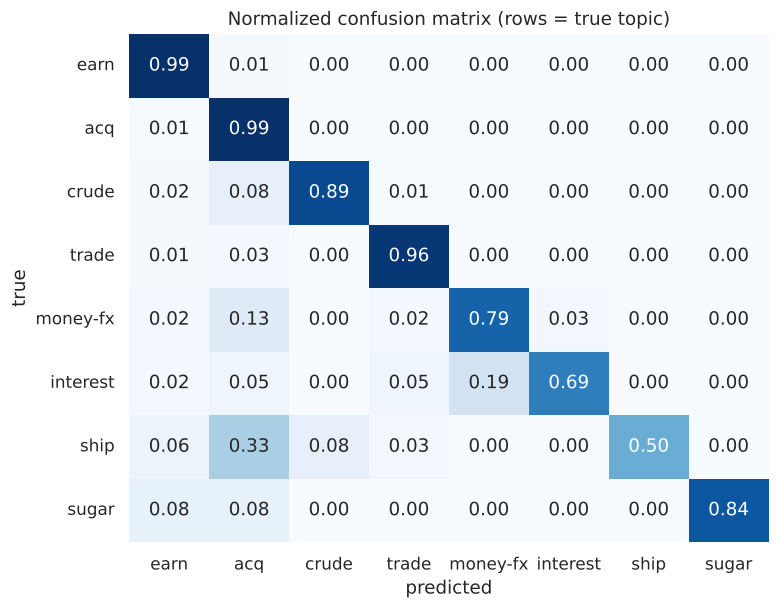

In [15]:
cmr = confusion_matrix(yr_te, yr_pred, labels=TOP, normalize="true")
plt.figure(figsize=(7.5, 6))
sns.heatmap(cmr, annot=True, fmt=".2f", cmap="Blues", xticklabels=TOP, yticklabels=TOP, cbar=False)
plt.title("Normalized confusion matrix (rows = true topic)"); plt.xlabel("predicted"); plt.ylabel("true"); plt.show()

---
## Part 3 — Sequence labeling: Named Entity Recognition (CoNLL-2002)
**Dataset:** CoNLL-2002 Spanish NER — newswire sentences where every word has a **BIO tag** for 4 entity types: PER (person), ORG (organization), LOC (location), MISC.
**Model:** a Conditional Random Field (CRF) with classic word features.

In [16]:
from nltk.corpus import conll2002
train_sents = list(conll2002.iob_sents("esp.train"))
test_sents  = list(conll2002.iob_sents("esp.testb"))
print(f"train = {len(train_sents)} sentences, test = {len(test_sents)} sentences")
ex = next(s for s in train_sents if 8 <= len(s) <= 14 and sum(t != "O" for _, _, t in s) >= 3)
pd.DataFrame(ex, columns=["word", "POS", "BIO tag"]).T

train = 8323 sentences, test = 1517 sentences


,0,1,2,3,4,5,6,7,8,9,10
word,Melbourne,(,Australia,),",",25,may,(,EFE,),.
POS,NP,Fpa,NP,Fpt,Fc,Z,NC,Fpa,NC,Fpt,Fp
BIO tag,B-LOC,O,B-LOC,O,O,O,O,O,B-ORG,O,O


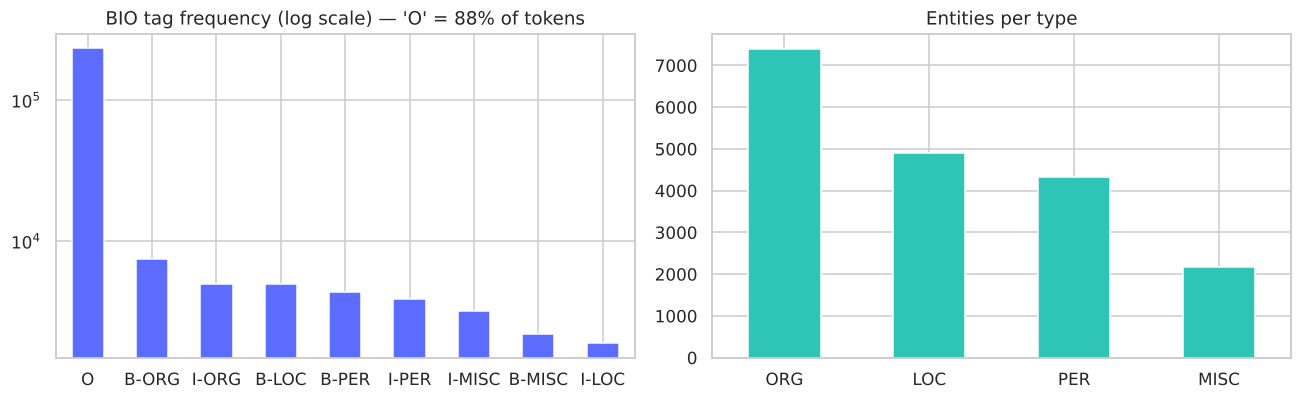

In [17]:
tags = collections.Counter(t for s in train_sents for _, _, t in s)
ents = collections.Counter(t[2:] for s in train_sents for _, _, t in s if t.startswith("B-"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
pd.Series(tags).sort_values(ascending=False).plot.bar(ax=ax[0], rot=0, color="#5B6CFF", logy=True)
ax[0].set_title(f"BIO tag frequency (log scale) — 'O' = {tags['O']/sum(tags.values()):.0%} of tokens")
pd.Series(ents).sort_values(ascending=False).plot.bar(ax=ax[1], rot=0, color="#2EC4B6"); ax[1].set_title("Entities per type")
plt.tight_layout(); plt.show()

In [18]:
import sklearn_crfsuite
def w2f(s, i):
    w = s[i][0]
    f = {"bias": 1, "w.lower": w.lower(), "w[-3:]": w[-3:], "w[-2:]": w[-2:], "w.isupper": w.isupper(),
         "w.istitle": w.istitle(), "w.isdigit": w.isdigit(), "pos": s[i][1]}
    if i > 0: f.update({"-1.w.lower": s[i-1][0].lower(), "-1.istitle": s[i-1][0].istitle(), "-1.pos": s[i-1][1]})
    else: f["BOS"] = True
    if i < len(s) - 1: f.update({"+1.w.lower": s[i+1][0].lower(), "+1.istitle": s[i+1][0].istitle(), "+1.pos": s[i+1][1]})
    else: f["EOS"] = True
    return f
feats  = lambda s: [w2f(s, i) for i in range(len(s))]
labels_ = lambda s: [t for _, _, t in s]
Xn_tr, yn_tr = [feats(s) for s in train_sents], [labels_(s) for s in train_sents]
Xn_te, yn_te = [feats(s) for s in test_sents],  [labels_(s) for s in test_sents]
def train_crf(X, y):
    return sklearn_crfsuite.CRF(algorithm="lbfgs", c1=0.1, c2=0.1, max_iterations=100).fit(X, y)
crf = train_crf(Xn_tr, yn_tr)
yn_pred = crf.predict(Xn_te)
print("CRF trained")

CRF trained


### 3.1 Token-level vs entity-level evaluation

Token accuracy (all tokens)             : 0.971
Token accuracy (entity tokens only)     : 0.786
Entity precision                        : 0.795
Entity recall                           : 0.781
Entity F1 (seqeval)                     : 0.788


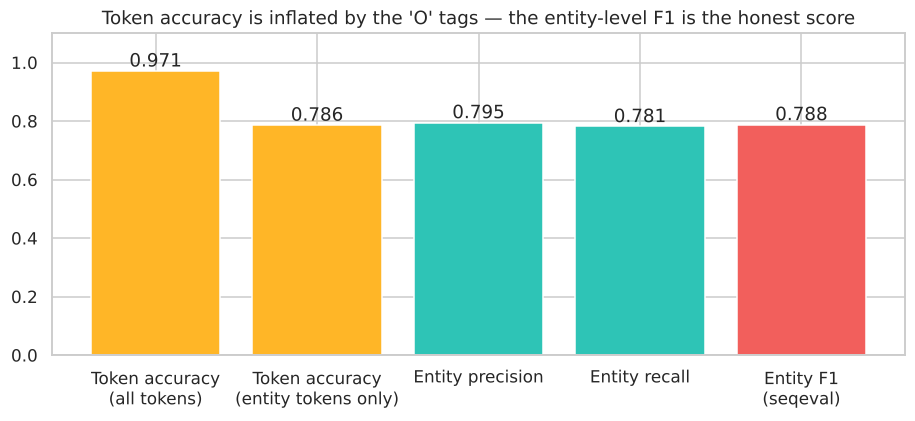

In [19]:
from seqeval.metrics import f1_score as ent_f1, precision_score as ent_p, recall_score as ent_r, classification_report as ent_report
flat_t = [t for s in yn_te for t in s]; flat_p = [t for s in yn_pred for t in s]
no_o   = [(a, b) for a, b in zip(flat_t, flat_p) if a != "O"]
cmp = {"Token accuracy\n(all tokens)": accuracy_score(flat_t, flat_p),
       "Token accuracy\n(entity tokens only)": np.mean([a == b for a, b in no_o]),
       "Entity precision": ent_p(yn_te, yn_pred), "Entity recall": ent_r(yn_te, yn_pred), "Entity F1\n(seqeval)": ent_f1(yn_te, yn_pred)}
for k, v in cmp.items(): print(f"{k.replace(chr(10), ' '):40s}: {v:.3f}")
plt.figure(figsize=(10, 3.8))
b = plt.bar(cmp.keys(), cmp.values(), color=["#FFB627", "#FFB627", "#2EC4B6", "#2EC4B6", "#F25F5C"])
plt.bar_label(b, fmt="%.3f"); plt.ylim(0, 1.1); plt.title("Token accuracy is inflated by the 'O' tags — the entity-level F1 is the honest score"); plt.show()

              precision    recall  f1-score   support

         LOC      0.807     0.774     0.790      1084
        MISC      0.663     0.497     0.568       340
         ORG      0.784     0.804     0.794      1400
         PER      0.842     0.880     0.861       735

   micro avg      0.795     0.781     0.788      3559
   macro avg      0.774     0.739     0.753      3559
weighted avg      0.791     0.781     0.785      3559



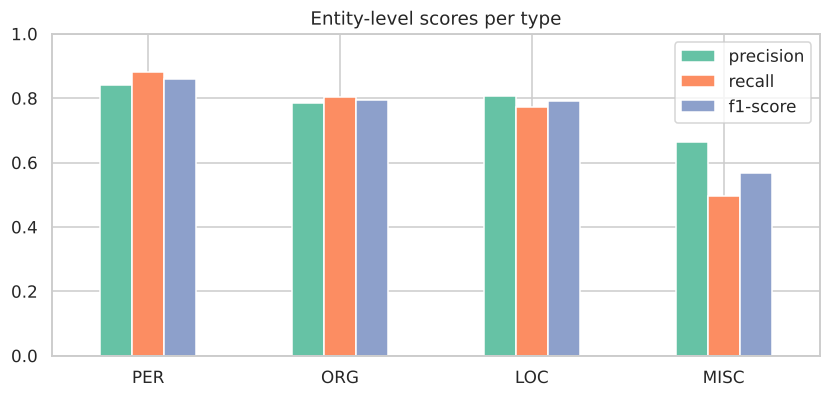

In [20]:
print(ent_report(yn_te, yn_pred, digits=3))
r = pd.DataFrame(ent_report(yn_te, yn_pred, output_dict=True)).T.loc[["PER", "ORG", "LOC", "MISC"]]
r[["precision", "recall", "f1-score"]].plot.bar(figsize=(9, 3.8), rot=0, ylim=(0, 1), title="Entity-level scores per type")
plt.show()

### 3.2 Error analysis: why entities are wrong
For every gold or predicted entity that does not match exactly we look for the cause:
**boundary error** (right type, wrong span — like *“Banque”* instead of *“Banque de France”*), **type error** (right span, wrong type), **missed** or **spurious** entity.

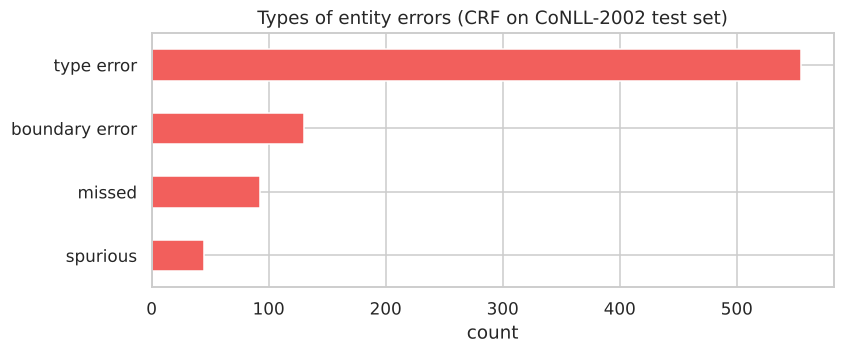

spurious           45
missed             93
boundary error    130
type error        555
dtype: int64


In [21]:
from seqeval.metrics.sequence_labeling import get_entities
errors = collections.Counter()
for t, p in zip(yn_te, yn_pred):
    G, P = set(get_entities(t)), set(get_entities(p))
    for g in G - P:
        ov = [q for q in P - G if not (q[2] < g[1] or q[1] > g[2])]
        if not ov: errors["missed"] += 1
        elif any(q[0] == g[0] for q in ov): errors["boundary error"] += 1
        else: errors["type error"] += 1
    for q in P - G:
        if not any(not (q[2] < g[1] or q[1] > g[2]) for g in G): errors["spurious"] += 1
s = pd.Series(errors).sort_values()
s.plot.barh(figsize=(8, 3), color="#F25F5C", title="Types of entity errors (CRF on CoNLL-2002 test set)"); plt.xlabel("count"); plt.show()
print(s)

Most errors are **type errors**: the span is right but the type is wrong. Which types get confused?

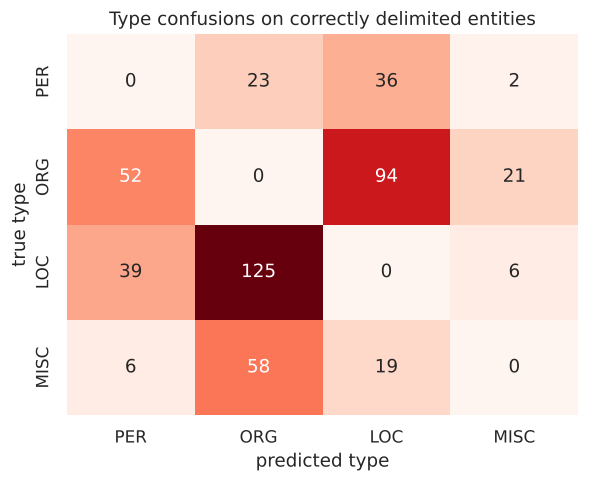

In [22]:
conf = collections.Counter()
for t, p in zip(yn_te, yn_pred):
    P = {(a, b): ty for ty, a, b in get_entities(p)}
    for ty, a, b in get_entities(t):
        if (a, b) in P and P[(a, b)] != ty: conf[(ty, P[(a, b)])] += 1
T4 = ["PER", "ORG", "LOC", "MISC"]
mat = pd.DataFrame([[conf[(g, q)] for q in T4] for g in T4], index=T4, columns=T4)
plt.figure(figsize=(6, 4.5)); sns.heatmap(mat, annot=True, fmt="d", cmap="Reds", cbar=False)
plt.title("Type confusions on correctly delimited entities"); plt.xlabel("predicted type"); plt.ylabel("true type"); plt.show()

### 3.3 Learning curve: the gap between token accuracy and entity F1

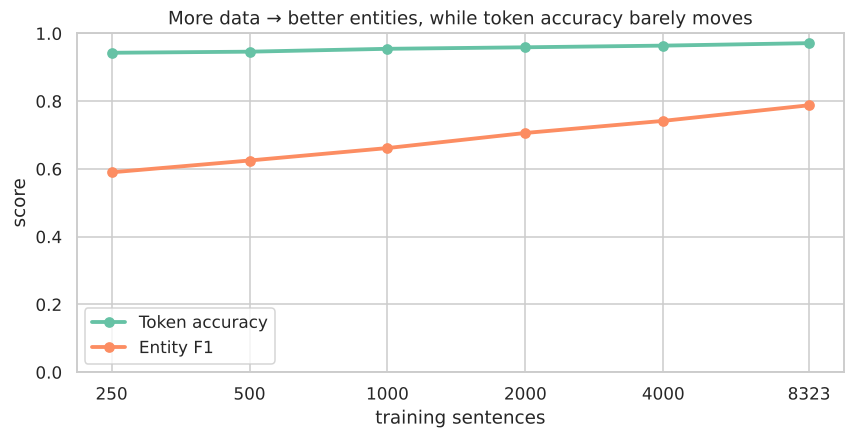

,training sentences,Token accuracy,Entity F1
0,250,0.943,0.590
1,500,0.946,0.625
2,1000,0.955,0.662
3,2000,0.959,0.706
4,4000,0.964,0.742
5,8323,0.971,0.788


In [23]:
sizes, curve = [250, 500, 1000, 2000, 4000, len(Xn_tr)], []
for n in sizes:
    p = train_crf(Xn_tr[:n], yn_tr[:n]).predict(Xn_te)
    curve.append({"training sentences": n, "Token accuracy": accuracy_score(flat_t, [t for s in p for t in s]), "Entity F1": ent_f1(yn_te, p)})
curve = pd.DataFrame(curve)
ax = curve.plot(x="training sentences", marker="o", lw=2.5, figsize=(9, 4), logx=True, ylim=(0, 1),
                title="More data → better entities, while token accuracy barely moves")
ax.set_xticks(sizes); ax.set_xticklabels(sizes); ax.minorticks_off()
plt.ylabel("score"); plt.show(); curve.round(3)

---
## Part 4 — Machine translation: French → English
**Dataset:** ComTrans — French–English sentence pairs from the European Parliament (Europarl).
**Models:** we train **IBM Model 1**, a classic statistical translation model, on 500, 3,000 and 12,000 sentence pairs, and translate word by word.
A *copy-the-source* baseline shows the minimum score.
These are simple systems, but they let us see **what each metric rewards**.

In [24]:
from nltk.corpus import comtrans
from nltk.translate import IBMModel1, AlignedSent
pairs = [( [w.lower() for w in a.mots], [w.lower() for w in a.words]) for a in comtrans.aligned_sents("alignment-en-fr.txt")]
test_pairs  = [p for p in pairs[-3000:] if 5 <= len(p[0]) <= 25][:400]
train_pairs = pairs[:-3000]
print(f"test = {len(test_pairs)} sentences, e.g. FR: {' '.join(test_pairs[0][0])}\n                       EN: {' '.join(test_pairs[0][1])}")

test = 400 sentences, e.g. FR: je les remercie pour ce travail .
                       EN: i offer them my thanks for their work .


In [25]:
unigram = collections.Counter(w for _, en in train_pairs for w in en)
def train_ibm(n):
    m = IBMModel1([AlignedSent(en, fr) for fr, en in train_pairs[:n]], 5)
    best = {}
    for e, row in m.translation_table.items():
        if e is None: continue
        for f, p in row.items():
            sc = p * (unigram[e] + 1) ** 0.3
            if sc > best.get(f, (None, 0))[1]: best[f] = (e, sc)
    return lambda fr: " ".join(best[w][0] if w in best else w for w in fr)
systems = {"Copy source (baseline)": lambda fr: " ".join(fr)}
for n in [500, 3000, 12000]:
    systems[f"IBM-1 ({n:,} pairs)"] = train_ibm(n)
refs = [" ".join(en) for _, en in test_pairs]
hyps = {name: [f(fr) for fr, _ in test_pairs] for name, f in systems.items()}
for i in range(2):
    print("FR  :", " ".join(test_pairs[i][0])); print("REF :", refs[i])
    for name in systems: print(f"{name[:22]:22s}:", hyps[name][i])
    print()

FR  : je les remercie pour ce travail .
REF : i offer them my thanks for their work .
Copy source (baseline): je les remercie pour ce travail .
IBM-1 (500 pairs)     : i the remercie for this work .
IBM-1 (3,000 pairs)   : i the thank for this work .
IBM-1 (12,000 pairs)  : i the thank for this work .

FR  : je voudrais tranquilliser les parlementaires qui ont parlé d' éventuelles sanctions .
REF : i would like to reassure all members who have spoken about possible sanctions .
Copy source (baseline): je voudrais tranquilliser les parlementaires qui ont parlé d' éventuelles sanctions .
IBM-1 (500 pairs)     : i like tranquilliser the parlementaires which have mentioned . éventuelles sanctions .
IBM-1 (3,000 pairs)   : i like tranquilliser the members which have mentioned . possible are .
IBM-1 (12,000 pairs)  : i like tranquilliser the parliament which have about . possible sanctions .



### 4.1 Corpus-level BLEU, chrF, TER and METEOR

In [26]:
import sacrebleu, logging
logging.getLogger("sacrebleu").setLevel(logging.ERROR)   # silence tokenization warnings
from nltk.translate.meteor_score import meteor_score
res = []
for name, h in hyps.items():
    bleu = sacrebleu.corpus_bleu(h, [refs])
    res.append({"system": name, "BLEU ↑": bleu.score, "chrF ↑": sacrebleu.corpus_chrf(h, [refs]).score,
                "TER ↓": sacrebleu.corpus_ter(h, [refs]).score,
                "METEOR ↑": 100 * np.mean([meteor_score([r.split()], x.split()) for r, x in zip(refs, h)]),
                "BP": bleu.bp, "len_ratio": bleu.sys_len / bleu.ref_len, **{f"p{i+1}": p for i, p in enumerate(bleu.precisions)}})
res = pd.DataFrame(res).set_index("system"); res[["BLEU ↑", "chrF ↑", "TER ↓", "METEOR ↑"]].round(2)

,BLEU ↑,chrF ↑,TER ↓,METEOR ↑
system,,,,
Copy source (baseline),1.37,27.54,96.76,11.21
IBM-1 (500 pairs),7.55,35.94,74.37,33.09
"IBM-1 (3,000 pairs)",10.37,40.57,69.61,39.36
"IBM-1 (12,000 pairs)",13.35,44.05,65.51,45.34


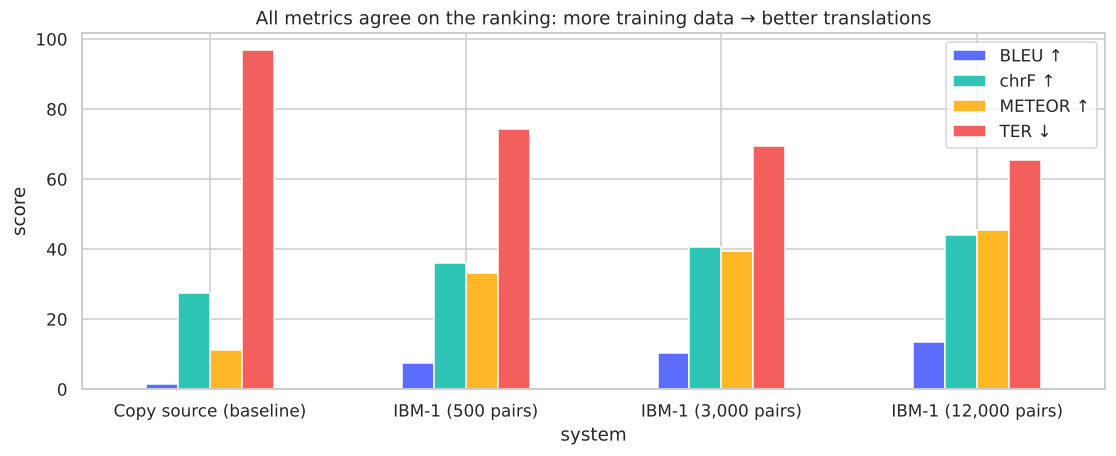

In [27]:
res[["BLEU ↑", "chrF ↑", "METEOR ↑", "TER ↓"]].plot.bar(figsize=(12, 4.2), rot=0, color=["#5B6CFF", "#2EC4B6", "#FFB627", "#F25F5C"])
plt.title("All metrics agree on the ranking: more training data → better translations"); plt.ylabel("score"); plt.show()

### 4.2 Inside BLEU: n-gram precisions and brevity penalty
Word-by-word systems keep the sentence length, so the brevity penalty is 1: the score comes only from the n-gram precisions, which collapse for longer n-grams.

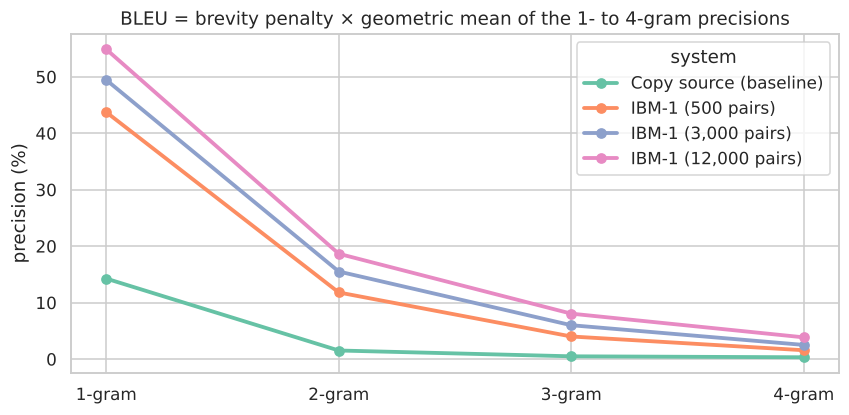

,brevity penalty,length ratio (hyp/ref)
system,,
Copy source (baseline),1.0,1.043
IBM-1 (500 pairs),1.0,1.040
"IBM-1 (3,000 pairs)",1.0,1.040
"IBM-1 (12,000 pairs)",1.0,1.040


In [28]:
res[["p1", "p2", "p3", "p4"]].T.plot(marker="o", lw=2.5, figsize=(9, 4))
plt.xticks(range(4), ["1-gram", "2-gram", "3-gram", "4-gram"]); plt.ylabel("precision (%)")
plt.title("BLEU = brevity penalty × geometric mean of the 1- to 4-gram precisions"); plt.show()
res[["BP", "len_ratio"]].rename(columns={"BP": "brevity penalty", "len_ratio": "length ratio (hyp/ref)"}).round(3)

### 4.3 Sentence-level scores: why BLEU is a corpus metric

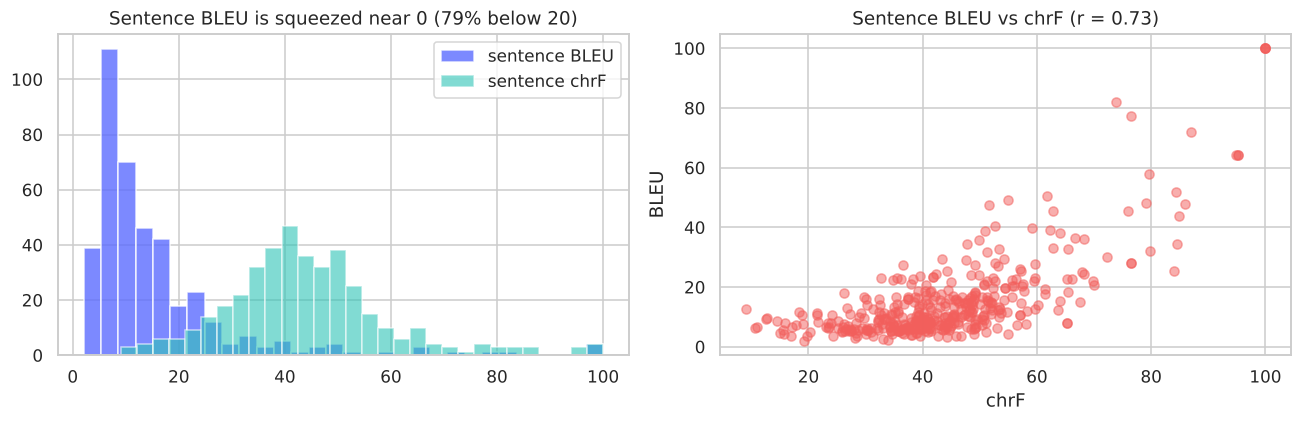

In [29]:
best_sys = list(systems)[-1]
sb = [sacrebleu.sentence_bleu(h, [r]).score for h, r in zip(hyps[best_sys], refs)]
sc = [sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(hyps[best_sys], refs)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(sb, bins=30, color="#5B6CFF", alpha=.8, label="sentence BLEU"); ax[0].hist(sc, bins=30, color="#2EC4B6", alpha=.6, label="sentence chrF")
ax[0].set_title(f"Sentence BLEU is squeezed near 0 ({np.mean(np.array(sb) < 20):.0%} below 20)"); ax[0].legend()
ax[1].scatter(sc, sb, alpha=.5, color="#F25F5C"); ax[1].set(xlabel="chrF", ylabel="BLEU", title=f"Sentence BLEU vs chrF (r = {np.corrcoef(sb, sc)[0, 1]:.2f})")
plt.tight_layout(); plt.show()

### 4.4 Is the difference significant? Bootstrap confidence intervals

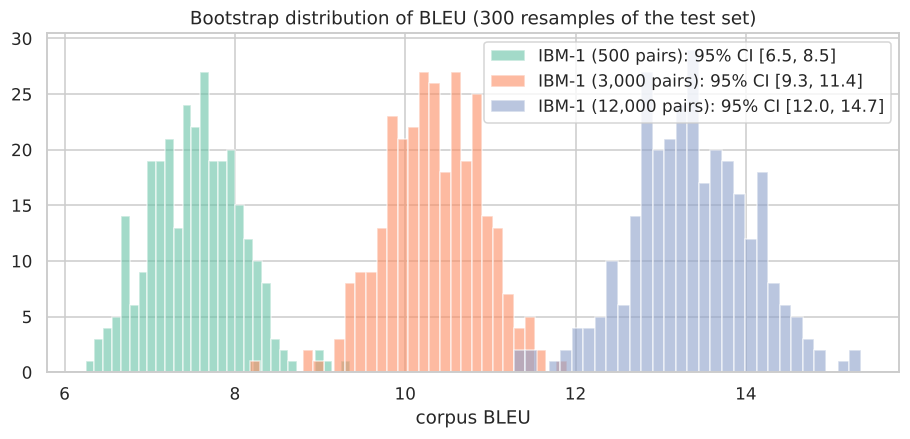

In [30]:
B, n = 300, len(refs); boot = {}
for name in list(systems)[1:]:
    vals = []
    for _ in range(B):
        idx = np.random.randint(0, n, n)
        vals.append(sacrebleu.corpus_bleu([hyps[name][i] for i in idx], [[refs[i] for i in idx]]).score)
    boot[name] = vals
plt.figure(figsize=(10, 4))
for name, v in boot.items():
    plt.hist(v, bins=30, alpha=.6, label=f"{name}: 95% CI [{np.percentile(v, 2.5):.1f}, {np.percentile(v, 97.5):.1f}]")
plt.xlabel("corpus BLEU"); plt.title("Bootstrap distribution of BLEU (300 resamples of the test set)"); plt.legend(); plt.show()

### 4.5 BLEU penalizes paraphrases

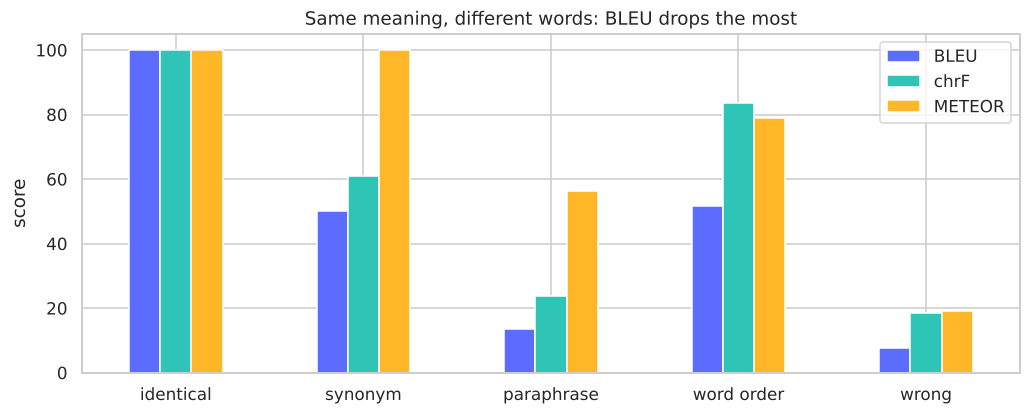

,BLEU,chrF,METEOR
identical,100.0,100.0,99.9
synonym,50.0,60.8,99.9
paraphrase,13.5,23.9,56.5
word order,51.7,83.7,78.9
wrong,7.5,18.5,19.0


In [31]:
ref = ["the cat is sitting on the mat ."]
cands = {"identical": "the cat is sitting on the mat .", "synonym": "the cat is seated on the mat .",
         "paraphrase": "a cat sits on the rug .", "word order": "on the mat the cat is sitting .", "wrong": "the dog runs in the park ."}
para = pd.DataFrame({k: {"BLEU": sacrebleu.sentence_bleu(v, ref).score, "chrF": sacrebleu.sentence_chrf(v, ref).score,
                         "METEOR": 100 * meteor_score([ref[0].split()], v.split())} for k, v in cands.items()}).T
para.plot.bar(figsize=(11, 4), rot=0, color=["#5B6CFF", "#2EC4B6", "#FFB627"])
plt.title("Same meaning, different words: BLEU drops the most"); plt.ylabel("score"); plt.show(); para.round(1)

---
## Conclusion
| Task | Dataset | What the experiments showed | Metric to report |
|---|---|---|---|
| Binary classification | Movie Reviews | Accuracy hides failures on imbalanced data; the threshold trades precision for recall | F1, ROC-AUC, PR curve |
| Multi-class | Reuters | Micro-F1 follows big classes, macro-F1 reveals weak small classes | Macro-F1 + per-class report |
| NER | CoNLL-2002 | Token accuracy stays high even when entities are wrong | Entity-level F1 (seqeval) |
| Translation | ComTrans (Europarl) | BLEU is unstable per sentence and penalizes paraphrases | BLEU + chrF (+ COMET), with confidence intervals |